In [2]:
# Import everything we need 

from pathlib import Path 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import random 
import yaml
import cv2

print("Done")

Done


In [3]:
# Defining Dataset paths and directories

# Project root
PROJECT_ROOT = Path("..").resolve()

# Dataset
DATASET_DIR = PROJECT_ROOT / "data" / "crack-seg"

# Dataset configuration
DATASET_YAML = DATASET_DIR / "crack-seg.yaml"

# Image directories
TRAIN_IMAGES = DATASET_DIR / "images" / "train"
VAL_IMAGES = DATASET_DIR / "images" / "val"
TEST_IMAGES = DATASET_DIR / "images" / "test"

# Label directories
TRAIN_LABELS = DATASET_DIR / "labels" / "train"
VAL_LABELS = DATASET_DIR / "labels" / "val"
TEST_LABELS = DATASET_DIR / "labels" / "test"

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("YAML         :", DATASET_YAML)

Project root : /home/priyanshu-sharma/Documents/CrackVision
Dataset      : /home/priyanshu-sharma/Documents/CrackVision/data/crack-seg
YAML         : /home/priyanshu-sharma/Documents/CrackVision/data/crack-seg/crack-seg.yaml


In [4]:
# Inspect crack-seg.yaml

with open(DATASET_YAML, "r") as file:
    dataset_config = yaml.safe_load(file)

dataset_config

{'path': 'crack-seg',
 'train': 'images/train',
 'val': 'images/val',
 'test': 'images/test',
 'names': {0: 'crack'},
 'download': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip'}

In [5]:
# Counting files in directories

def count_files(directory, extensions):
    return sum(
        1
        for file in directory.iterdir()
        if file.is_file() and file.suffix.lower() in extensions
    )

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
LABEL_EXTENSIONS = {".txt"}

splits = {
    "Train": (TRAIN_IMAGES, TRAIN_LABELS),
    "Validation": (VAL_IMAGES, VAL_LABELS),
    "Test": (TEST_IMAGES, TEST_LABELS),
}

for split_name, (image_dir, label_dir) in splits.items():
    image_count = count_files(image_dir, IMAGE_EXTENSIONS)
    label_count = count_files(label_dir, LABEL_EXTENSIONS)

    print(f"{split_name:12s} | "
          f"Images: {image_count:5d} | "
          f"Labels: {label_count:5d}"
          )

Train        | Images:  3717 | Labels:  3717
Validation   | Images:   200 | Labels:   200
Test         | Images:   112 | Labels:   112


Found 3717 training images.
Image: 10.rf.1be181322657e5592be06e9ed277e0b3.jpg
Shape: (416, 416, 3)


(np.float64(-0.5), np.float64(415.5), np.float64(415.5), np.float64(-0.5))

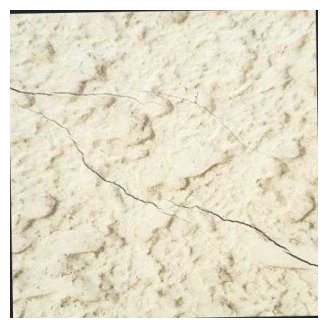

In [6]:
# Looking at one actual image

train_images = sorted(
    [
        file
        for file in TRAIN_IMAGES.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS 
    ]
)

print(f"Found {len(train_images)} training images.")

sample_image_path = train_images[0]

image = cv2.imread(str(sample_image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image:", sample_image_path.name)
print("Shape:", image.shape)

plt.figure(figsize=(14, 4))
plt.imshow(image_rgb)
plt.axis("off")

In [7]:
# Finding a labeled image

def find_labeled_image(image_dir, label_dir):
    images = sorted(
        file
        for file in image_dir.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    )

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        if label_path.exists() and label_path.stat().st_size > 0:
            return image_path, label_path
        return None, None

sample_image_path, sample_label_path = find_labeled_image(
    TRAIN_IMAGES,
    TRAIN_LABELS
)

print("Image:", sample_image_path)
print("Label:", sample_label_path)

Image: /home/priyanshu-sharma/Documents/CrackVision/data/crack-seg/images/train/10.rf.1be181322657e5592be06e9ed277e0b3.jpg
Label: /home/priyanshu-sharma/Documents/CrackVision/data/crack-seg/labels/train/10.rf.1be181322657e5592be06e9ed277e0b3.txt


In [8]:
# Read the raw annotation

with open(sample_label_path, "r") as file:
    label_lines = [line.strip() for line in file if line.strip()]

print(f"Number of annpotated objects: {len(label_lines)}")

for i, line in enumerate(label_lines[:5]):
    print(f"\nAnnotation {i + 1}:")
    print(line)

Number of annpotated objects: 4

Annotation 1:
0 0 0.2590149182692308 0.01704840144230769 0.2660720360576923 0.049245887019230765 0.2728594711538462 0.08973430528846153 0.27816592307692306 0.11705254807692309 0.2776890817307692 0.1383970673076923 0.2753121201923077 0.16566867548076925 0.2721635673076923 0.19660846153846154 0.27496416826923076 0.23706190384615383 0.27826683653846157 0.27152996394230766 0.2790014567307692 0.3107257019230769 0.27831729326923077 0.3309407620192308 0.27930069951923076 0.36904202403846154 0.2839806899038461 0.38935035576923077 0.29030751923076925 0.4049776418269231 0.30072484374999997 0.4384211730769231 0.3108311826923077 0.4644817139423077 0.30636750721153844 0.4835323461538461 0.3087075 0.5025829735576923 0.3110474951923077 0.5048302283653846 0.30365882932692306 0.4915784423076923 0.2932000408653846 0.4701289951923077 0.28956565384615385 0.44279909375 0.2893745673076923 0.41661030769230767 0.28649103846153845 0.3950209543269231 0.27484151923076927 0.365233

In [9]:
# Parse one polygon 

def parse_yolo_segmentation_line(line):
    values = line.split()

    class_id = int(values[0])
    coordinates = np.array(
        [float(value) for value in values[1:]],
        dtype=np.float32
    )

    if len(coordinates) % 2 != 0:
        raise ValueError("Segmentation coordinates must contain x/y pairs.")

    polygon = coordinates.reshape(-1, 2)

    return class_id, polygon

class_id, polygon = parse_yolo_segmentation_line(label_lines[0])
print("Class ID:", class_id)
print("Number of polygon points:", len(polygon))

print("/nFirst 5 normalized points:")
print(polygon[:5])


Class ID: 0
Number of polygon points: 41
/nFirst 5 normalized points:
[[0.         0.2590149 ]
 [0.0170484  0.26607203]
 [0.04924589 0.27285948]
 [0.08973431 0.27816594]
 [0.11705255 0.27768907]]


In [10]:
# Convert normalized coordinates to pixel coordinates

image = cv2.imread(str(sample_image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

polygon_pixels = polygon.copy()

polygon_pixels[:, 0] *= width
polygon_pixels[:, 1] *= height

polygon_pixels = polygon_pixels.astype(np.int32)

print("Image size:")
print("Width:", width)
print("Height:", height)

print("/nFirst 5 pixel coordinates:")
print(polygon_pixels[:5])

Image size:
Width: 416
Height: 416
/nFirst 5 pixel coordinates:
[[  0 107]
 [  7 110]
 [ 20 113]
 [ 37 115]
 [ 48 115]]


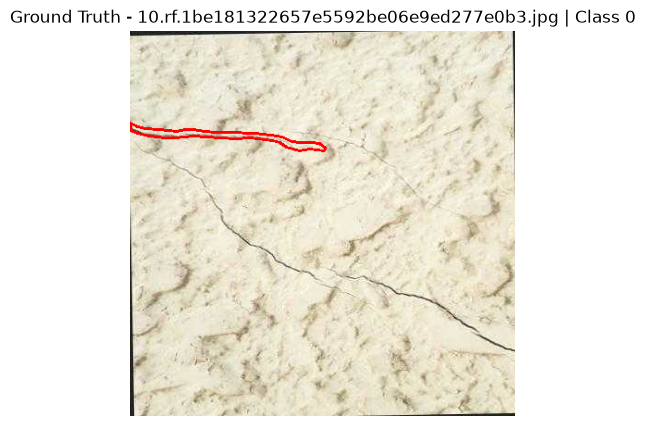

In [11]:
# Ground-truth Crack

overlay = image_rgb.copy()

cv2.polylines(
    overlay, 
    [polygon_pixels],
    isClosed = True, 
    color = (255, 0, 0), 
    thickness=2
)

plt.figure(figsize=(16, 5))
plt.imshow(overlay)
plt.axis("off")
plt.title(f"Ground Truth - {sample_image_path.name} | Class {class_id}")
plt.show()

In [12]:
# Function for creating the full mask 

def create_segmentation_mask(image_shape, label_path):
    """
    Create a binary segmentation mask from a YOLO segmentation label file.
    Parameters:
    image shape: tuple 
    Image shape as returned by OpenCV (height, width, channels)

    label_path: Path
    Path to the YOLO segmentation label file.

    Returns
    mask: np.ndarray
    Binary mask with: 
    0 = background
    255 = crack
    """

    height, width = image_shape[:2]

    mask = np.zeros((height, width), dtype=np.uint8)

    with open(label_path, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    for line in lines:
        class_id, polygon = parse_yolo_segmentation_line(line)

        polygon_pixels = polygon.copy()
        polygon_pixels[:, 0] *= width
        polygon_pixels[:, 1] *= height
        polygon_pixels = polygon_pixels.astype(np.int32)

        cv2.fillPoly(mask, [polygon_pixels], 255)
    return mask

In [13]:
# Create the mask for our sample 

mask = create_segmentation_mask(
    image.shape, 
    sample_label_path
)
print("Mask shape:", mask.shape)
print("Unique mask values:", np.unique(mask))

Mask shape: (416, 416)
Unique mask values: [  0 255]


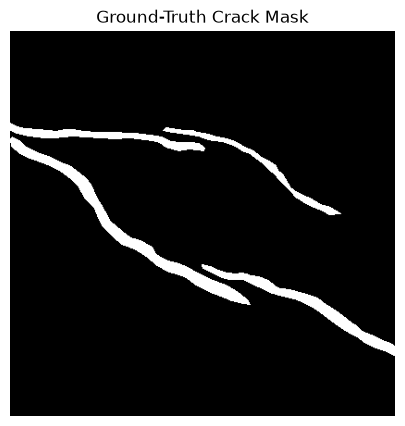

In [14]:
# Visualize the mask

plt.figure(figsize=(16, 5))
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.title("Ground-Truth Crack Mask")

plt.show()

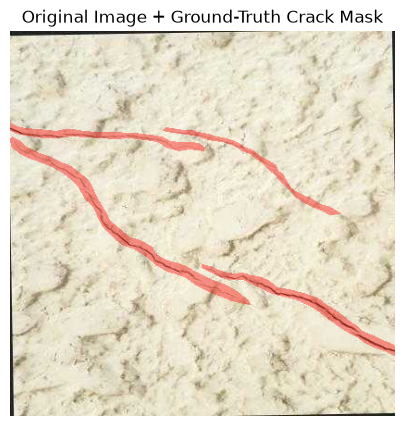

In [15]:
# Overlay the mask on the original image

overlay = image_rgb.copy()

crack_pixels = mask > 0

overlay[crack_pixels] = (
    0.6 * overlay[crack_pixels]
    + 0.4 * np.array([255, 0, 0])
)

overlay = overlay.astype(np.uint8)

plt.figure(figsize=(16, 5))
plt.imshow(overlay)
plt.axis("off")
plt.title("Original Image + Ground-Truth Crack Mask")
plt.show()

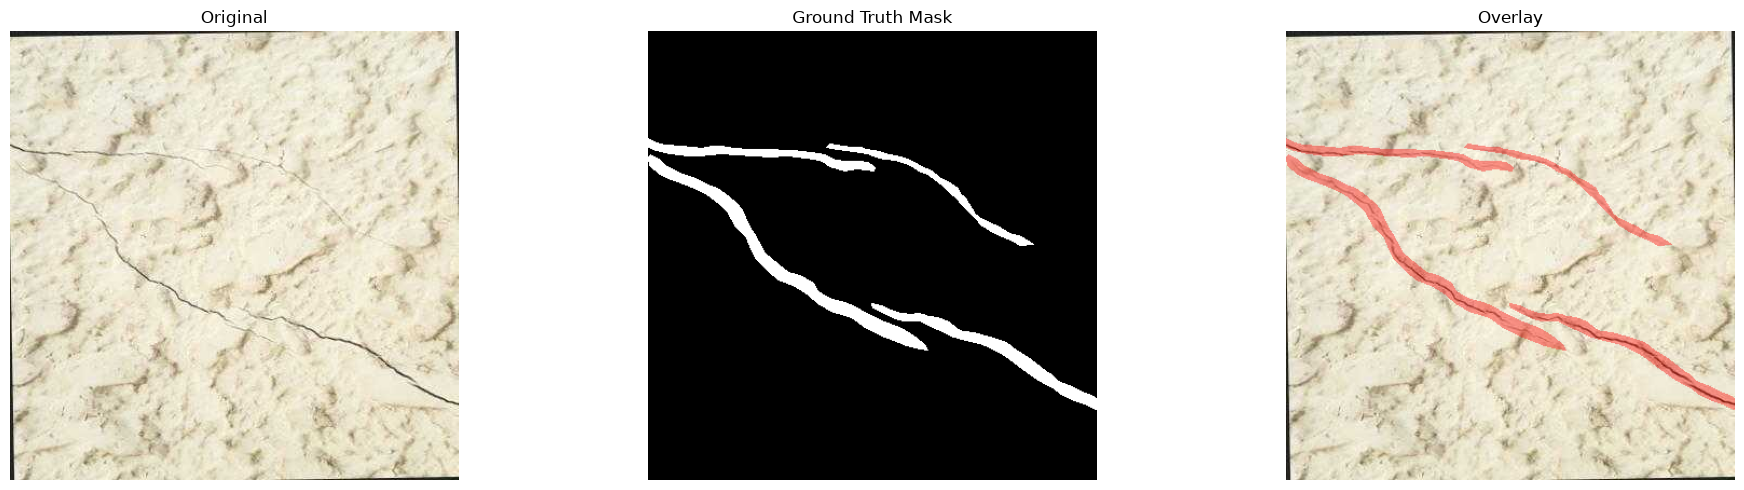

In [16]:
# Put all three views together 
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Randomly sample images

random.seed(42)
sample_count = 9

sample_paths = random.sample(
    train_images, 
    min(sample_count, len(train_images))
)

print("Selected images:")
for path in sample_paths: 
    print(path.name)

Selected images:
3239.rf.032d8dfa6c0943ac25c4170b48481bf0.jpg
1866.rf.05020fc8793a394a8d22a15c351b424b.jpg
1652.rf.206ee3eaf0f784c10b6f95062a6a03a2.jpg
3408.rf.35717230235726858903d839371c9390.jpg
2178.rf.5bf5802135338699e18283665fe9db14.jpg
2124.rf.ab4825bfa37f599bc6f9b1baa7f48d8a.jpg
2087.rf.9a992b76bce618c4b6bed08734758f16.jpg
1920.rf.5c8388d6069918d0725c54f1ecfd31a7.jpg
3401.rf.52e301990ea5c305275e5c3682fe35f0.jpg


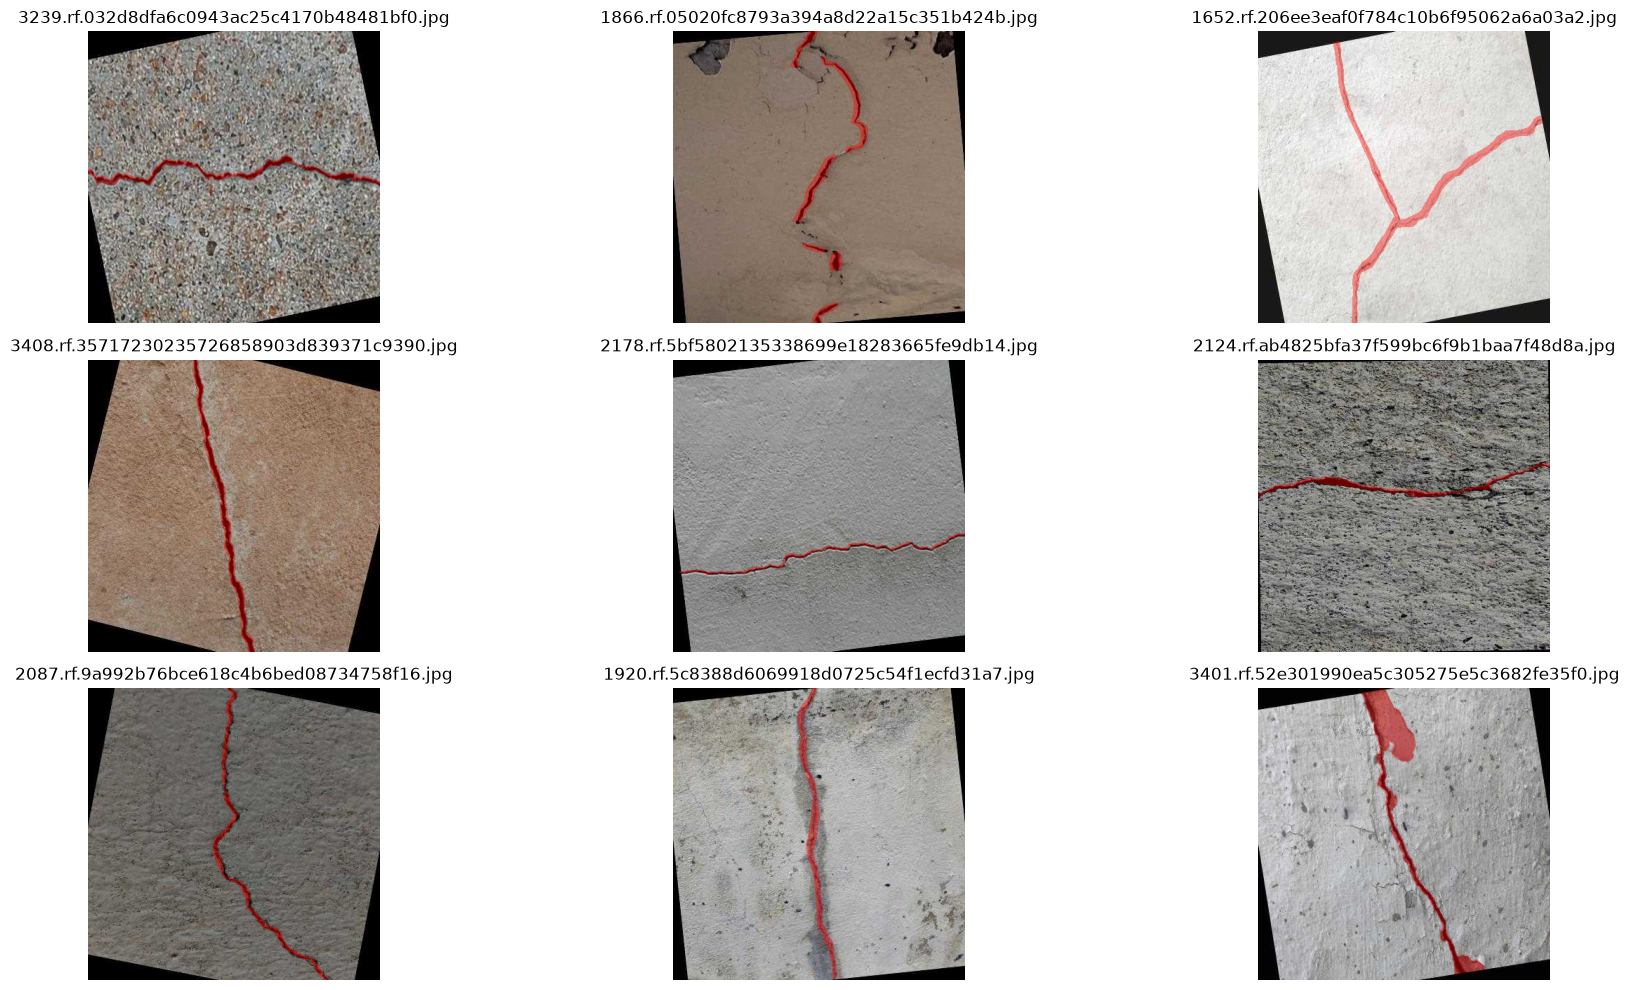

In [18]:
# Visualize multiple ground-truth overlays 

fig, axes = plt.subplots(3, 3, figsize=(20, 10))

for ax, image_path in zip(axes.flat, sample_paths):
    label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    if label_path.exists() and label_path.stat().st_size > 0:
        mask = create_segmentation_mask(
            image.shape,
            label_path
        )

        overlay = image_rgb.copy()

        crack_pixels = mask > 0

        overlay[crack_pixels] = (
            0.6 * overlay[crack_pixels]
            + 0.4 * np.array([255, 0, 0])
        )
        overlay = overlay.astype(np.uint8)
        ax.imshow(overlay)

    else: 
        ax.imshow(image_rgb)
        ax.set_title("No Annotation")

    ax.axis("off")
    ax.set_title(image_path.name)

plt.tight_layout()
plt.show()

In [19]:
# Collecting statistics for every image

dataset_records = []
annotation_issues = []
orphan_label_files = []

class_names = dataset_config.get("names", {})

if isinstance(class_names, dict):
    allowed_class_ids = {int(key) for key in class_names}
else:
    allowed_class_ids = set(range(len(class_names)))

for split_name, (image_dir, label_dir) in splits.items():
    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    label_paths = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in image_paths}
    label_stems = {p.stem for p in label_paths}

    for orphan in sorted(label_stems - image_stems):
        orphan_label_files.append({
            "split": split_name,
            "label": orphan
        })

    for image_path in image_paths:

        label_path = label_dir / f"{image_path.stem}.txt"
        image = cv2.imread(str(image_path))

        if image is None:
            annotation_issues.append({
                "split": split_name,
                "image": image_path.name, 
                "issue": "Image could not be opened"
            })
            continue

        height, width = image.shape[:2]
        mask = np.zeros((height, width), dtype=np.uint8)

        label_exists = label_path.exists()
        label_lines = []

        if label_exists:
            with open(label_path, "r") as file:
                label_lines = [
                    line.strip()
                    for line in file
                    if line.strip()
                ]

        valid_polygon_count = 0

        for line_number, line in enumerate(label_lines, start=1):

            try:
                class_id, polygon = parse_yolo_segmentation_line(line) 

                if class_id not in allowed_class_ids:
                    raise ValueError(
                        f"Unknown class ID: {class_id}"
                    )

                if len(polygon) < 3:
                    raise ValueError(
                        "Polygon has fewer than 3 points"
                    )

                if not np.isfinite(polygon).all():
                    raise ValueError(
                        "Polygon contains non-finite coordinates"
                    )

                if np.any((polygon < 0) | (polygon > 1)):
                    annotation_issues.append({
                        "split": split_name,
                        "image": image_path.name,
                        "issue": (
                            f"Coordinates outside [0, 1]"
                            f"on label line {line_number}"
                        )
                    })

                polygon = np.clip(polygon, 0, 1)

                polygon_pixels = polygon.copy()
                polygon_pixels[:, 0] *= width
                polygon_pixels[:, 1] *= height
                polygon_pixels = polygon_pixels.astype(np.int32)

                cv2.fillPoly(mask, [polygon_pixels], 255)
                valid_polygon_count += 1

            except (ValueError, IndexError, TypeError) as error:
                annotation_issues.append({
                    "split": split_name, 
                    "image": image_path.name, 
                    "issue": (
                        f"Invalid annotation line {line_number}: "
                        f"{error}"
                    )
                })

        crack_pixels = int(np.count_nonzero(mask))
        total_pixels = height * width

        coverage_percent = (
            100 * crack_pixels / total_pixels
            if total_pixels else 0
        )

        dataset_records.append({
            "split": split_name,
            "image_name": image_path.name,
            "width": width,
            "height": height,
            "channels": image.shape[2] if image.ndim == 3 else 1,
            "label_exists": label_exists,
            "empty_label": label_exists and len(label_lines) == 0,
            "raw_annotation_count": len(label_lines),
            "valid_polygon_count": valid_polygon_count,
            "crack_pixels": crack_pixels,
            "crack_coverage_percent": coverage_percent
        })

dataset_audit = pd.DataFrame(dataset_records)

print("Dataset audit completed!")
print(f"Images inspected: {len(dataset_audit)}")
print(f"Annotation issues flagged: {len(annotation_issues)}")
print(f"Label files without matching images: {len(orphan_label_files)}")

Dataset audit completed!
Images inspected: 4029
Annotation issues flagged: 0
Label files without matching images: 0


In [20]:
# Summarize the splits 

summary = dataset_audit.groupby("split").agg(
    images=("image_name", "count"),
    missing_label_files=(
        "label_exists",
        lambda s: int((~s).sum())
    ),
    empty_label_files=("empty_label", "sum"),
    images_with_polygons=(
        "valid_polygon_count",
        lambda s: int((s > 0).sum())
    ),
    total_polygons=("valid_polygon_count", "sum"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    mean_coverage_percent=("crack_coverage_percent", "mean"),
    median_coverage_percent=("crack_coverage_percent", "median"),
    max_coverage_percent=("crack_coverage_percent", "max")
)

summary

,images,missing_label_files,empty_label_files,images_with_polygons,total_polygons,median_width,median_height,mean_coverage_percent,median_coverage_percent,max_coverage_percent
split,,,,,,,,,,
Test,112,0,0,112,148,416.0,416.0,1.984834,1.615373,5.905025
Train,3717,0,0,3717,4893,416.0,416.0,2.164593,1.808085,10.886649
Validation,200,0,1,199,249,416.0,416.0,2.024778,1.689915,6.863096


In [21]:
# Inspect the image resolutions

resolution_counts = (
    dataset_audit
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .rename("image_count")
    .reset_index()
)

resolution_counts.head(15)

,width,height,image_count
0,416,416,4029


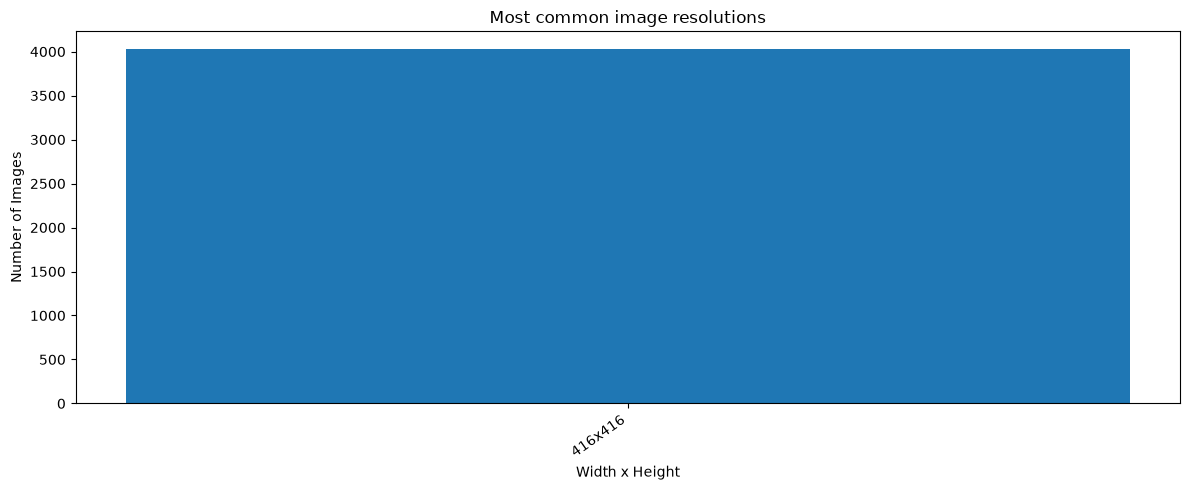

In [22]:
# visualizing the most common resolutions

top_resolutions = resolution_counts.head(10).copy()

top_resolutions["resolution"] = (
    top_resolutions["width"].astype(int).astype(str)
    + "x"
    + top_resolutions["height"].astype(int).astype(str)
)

plt.figure(figsize=(12, 5))

plt.bar(
    top_resolutions["resolution"],
    top_resolutions["image_count"]
)

plt.title("Most common image resolutions")
plt.xlabel("Width x Height")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

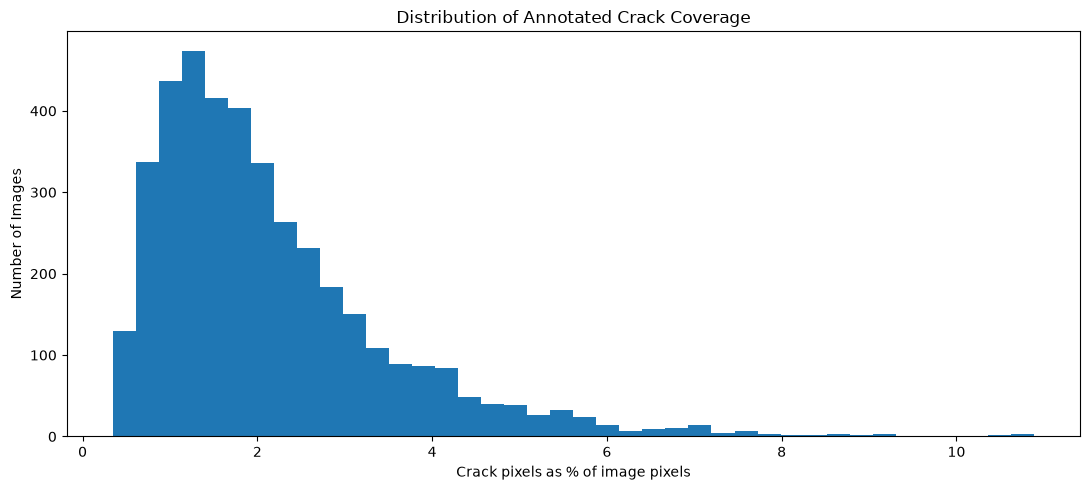

count    4028.000000
mean        2.153190
std         1.373659
min         0.344397
25%         1.204234
50%         1.803462
75%         2.707216
90%         3.968022
95%         4.870418
max        10.886649
Name: crack_coverage_percent, dtype: float64

In [23]:
# Analyze crack coverage
images_with_cracks = dataset_audit[
    dataset_audit["valid_polygon_count"] > 0
]

plt.figure(figsize=(11, 5))

plt.hist(
    images_with_cracks["crack_coverage_percent"],
    bins=40
)

plt.title("Distribution of Annotated Crack Coverage")
plt.xlabel("Crack pixels as % of image pixels")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

# Inspecting the numerical values

coverage_stats = images_with_cracks[
    "crack_coverage_percent"
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

coverage_stats

In [24]:
# Finding the smallest annotated regions

smallest_cracks = (
    images_with_cracks
    .sort_values("crack_coverage_percent")
    [[
        "image_name",
        "split",
        "width",
        "height",
        "valid_polygon_count",
        "crack_coverage_percent"
    ]]
    .head(15)
)

smallest_cracks

,image_name,split,width,height,valid_polygon_count,crack_coverage_percent
513,1889.rf.2edf2c7d4f7933365c7c3d9676c7eb4e.jpg,Train,416,416,2,0.344397
3952,2240.rf.66f2163089851cb1d7874b913e592b94.jpg,Test,416,416,2,0.357110
1880,2512.rf.e5c43bbcca138ef72860b7e56643ab36.jpg,Train,416,416,1,0.383691
1878,2512.rf.a1af476c4b0391bbf84175d67b244242.jpg,Train,416,416,1,0.421251
3854,3195.rf.e3ae0cd9816c8c0601044343d91cbc09.jpg,Validation,416,416,2,0.428185
1698,2439.rf.3ff88dc6f25f0a92f11445776c829de3.jpg,Train,416,416,1,0.428763
1116,2174.rf.87bdcbc9082f5a6e157a6a755624ab12.jpg,Train,416,416,1,0.435697
1118,2174.rf.bfb41da636dca811e4be029b970db9b6.jpg,Train,416,416,1,0.441476
1213,2216.rf.a6625e9908debc2f0c4c9cb9e2dc593f.jpg,Train,416,416,2,0.442631
1699,2439.rf.77cee75273031b7efe064c4c79d3434c.jpg,Train,416,416,1,0.446676


In [25]:
def display_audit_samples(image_names, split_name="Train"):
    image_dir, label_dir = splits[split_name]

    selected = dataset_audit[
        (dataset_audit["split"] == split_name)
        & (dataset_audit["image_name"].isin(image_names))
    ]

    if selected.empty:
        print("No images found for this split.")
        return

    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(16, 4 * len(selected)),
        squeeze=False
    )

    for row, record in enumerate(selected.itertuples()):
        image_path = image_dir / record.image_name
        label_path = label_dir / f"{image_path.stem}.txt"

        image = cv2.imread(str(image_path))
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = create_segmentation_mask(
            image.shape,
            label_path
        ) if label_path.exists() else np.zeros(
            image.shape[:2], dtype=np.uint8
        )

        overlay = image_rgb.copy()
        pixels = mask > 0

        overlay[pixels] = (
            0.55 * overlay[pixels]
            + 0.45 * np.array([255, 0, 0])
        ).astype(np.uint8)

        axes[row, 0].imshow(image_rgb)
        axes[row, 0].set_title(record.image_name + " — Original")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(overlay)
        axes[row, 1].set_title(
            f"Coverage: {record.crack_coverage_percent:.4f}%"
        )
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()

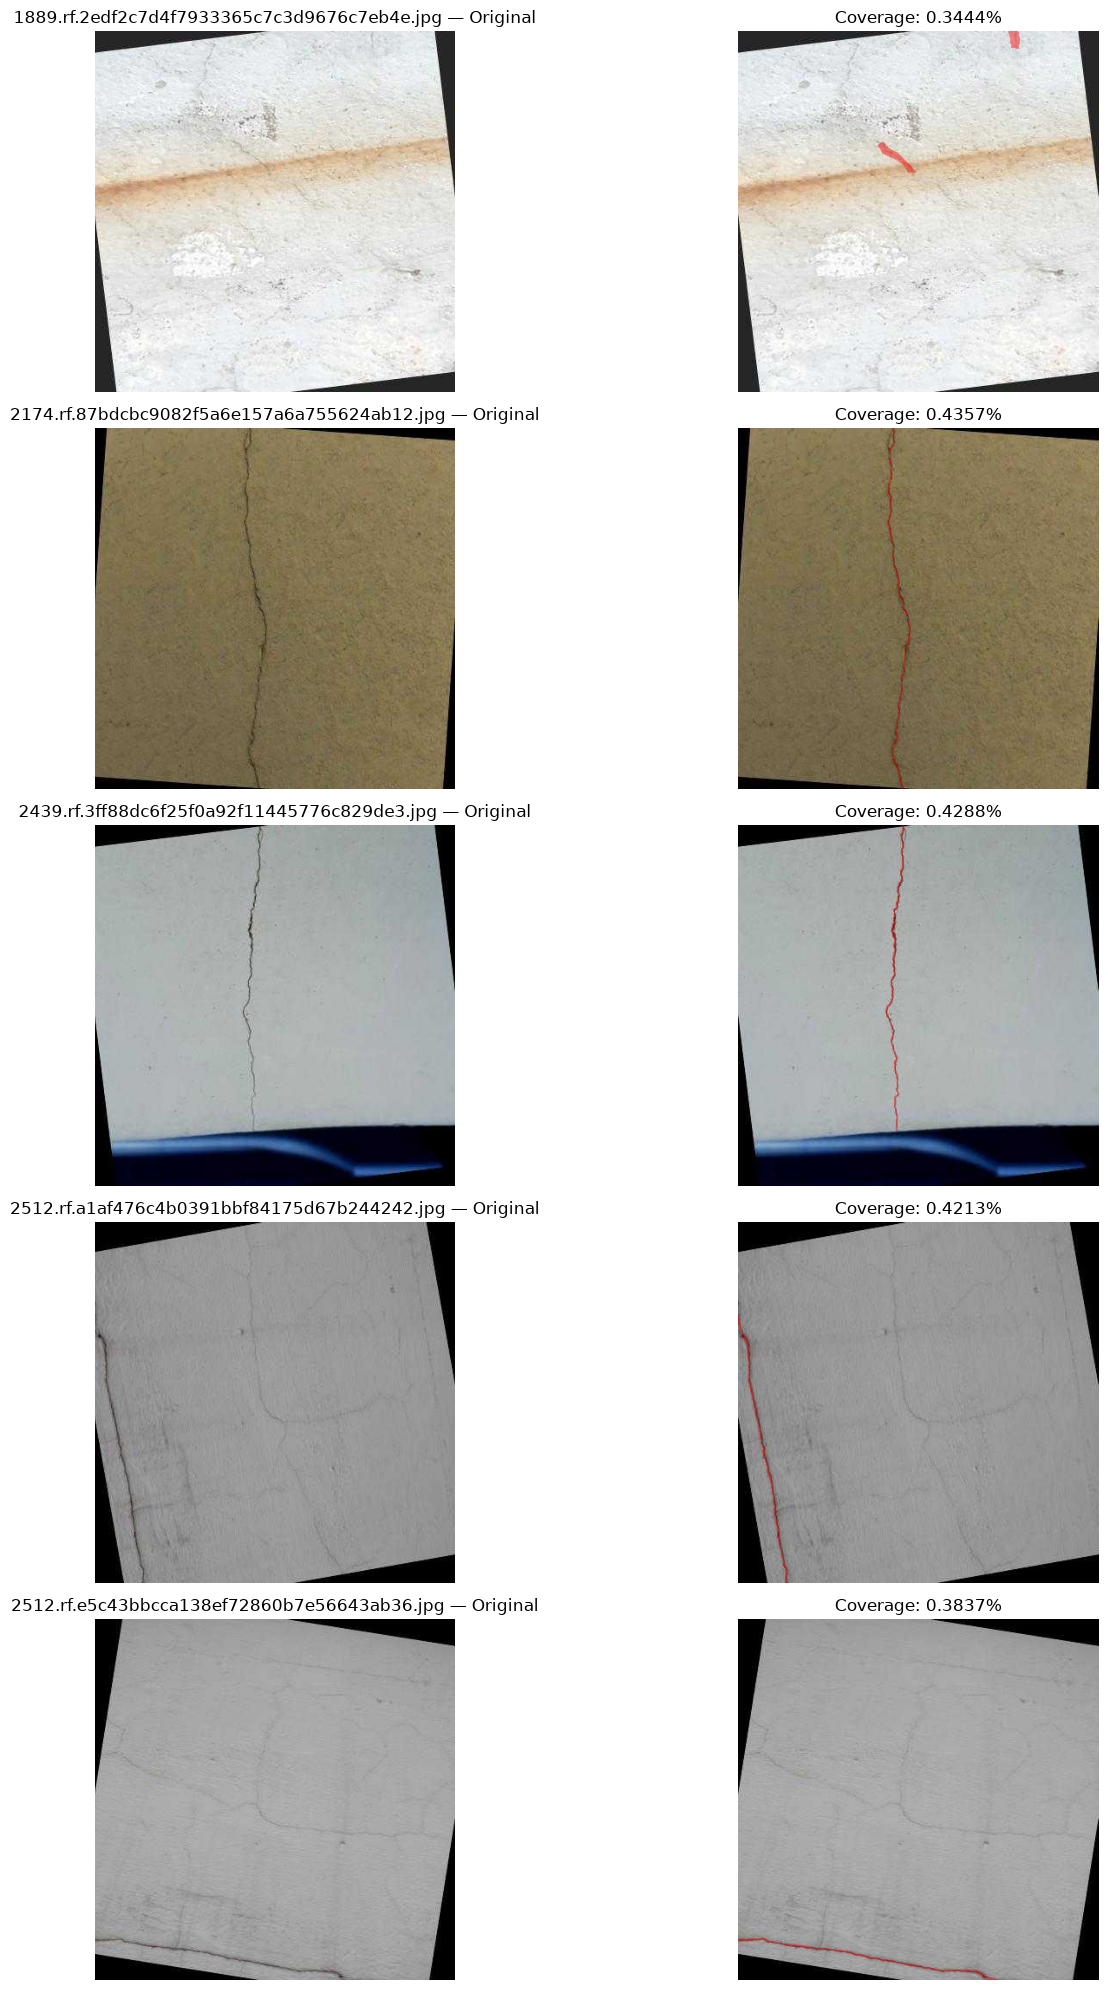

In [26]:
display_audit_samples(
    dataset_audit[
        (dataset_audit["split"] == "Train")
        & (dataset_audit["valid_polygon_count"] > 0)
    ]
    .nsmallest(5, "crack_coverage_percent")["image_name"]
    .tolist()
)

In [28]:
# Review data-quality warnings
print("UNREADABLE OR INVALID ANNOTATIONS")

if annotation_issues:
    issues_df = pd.DataFrame(annotation_issues)
    display(issues_df.head(30))
    print(f"Total issues flagged: {len(issues_df)}")
else:
    print("No annotation issues flagged.")

print("\nLABEL FILES WITHOUT MATCHING IMAGES")

if orphan_label_files:
    display(pd.DataFrame(orphan_label_files).head(30))
else:
    print("No orphan label files found.")

print("\nMISSING LABEL FILES")

missing_labels = dataset_audit[
    ~dataset_audit["label_exists"]
][["split", "image_name"]]

display(missing_labels.head(20))
print(f"Images without label files: {len(missing_labels)}")

UNREADABLE OR INVALID ANNOTATIONS
No annotation issues flagged.

LABEL FILES WITHOUT MATCHING IMAGES
No orphan label files found.

MISSING LABEL FILES


,split,image_name


Images without label files: 0
